## **1 частина**

### 1/2 Імпорт необхідних бібліотек та завантаження даних
Підключення бібліотек для обробки та аналізу даних. Зчитування CSV-файлів із даними про користувачів, події та підписки.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

users = pd.read_csv("users.csv")
events = pd.read_csv("events.csv")
subscriptions = pd.read_csv("subscriptions.csv")

print("Users:", users.shape)
print("Events:", events.shape)
print("Subscriptions:", subscriptions.shape)


Users: (4030, 5)
Events: (42420, 4)
Subscriptions: (323, 7)



### 3. Первинний перегляд даних
Перевірка структури таблиць та перших записів.



In [2]:

display(users.head())
display(events.head())
display(subscriptions.head())


,user_id,registration_date,country,platform,marketing_channel
0,3340,2026-01-17,NaN,Android,google_ads
1,2743,2026-04-11,DE,Android,referral
2,3883,2026-08-02,BR,iOS,referral
3,1879,07.03.2026,Poland,iOS,google_ads
4,1658,2026-07-01,DE,iOS,organic


,user_id,event_name,event_timestamp,event_params
0,3649.0,view_content,2026-07-04 04:34:56,content_type=video
1,4771.0,view_content,2026/05/16 09:33,content_type=video
2,1785.0,view_content,2026/04/09 20:42,content_type=course
3,1269.0,view_content,2026-07-14 05:56:10,content_type=quiz
4,2043.0,view_content,2026-04-01 22:13:11,content_type=podcast


,subscription_id,user_id,start_date,end_date,amount,currency,plan_type
0,213,3606,2026-04-19,2026-05-19,8.99,USD,monthly
1,294,4615,2026-07-12,NaN,8.99,USD,monthly
2,162,3003,2026-02-17,2026-03-19,8.99,USD,monthly
3,31,1384,2026-02-28,NaN,79.99,USD,annual
4,235,3863,2026-01-19,2026-02-18,8.99,usd,monthly



### 4. Перевірка якості даних
Аналіз пропущених значень, дублікатів і типів даних.



In [3]:

datasets = {
    "Users": users,
    "Events": events,
    "Subscriptions": subscriptions
}

for name, df in datasets.items():
    print(f"\n--- {name} ---")
    print("Типи даних:")
    print(df.dtypes)

    print("\nПропущені значення:")
    print(df.isna().sum())

    print("\nКількість дублікатів:", df.duplicated().sum())
    print("-" * 40)



--- Users ---
Типи даних:
user_id              int64
registration_date      str
country                str
platform               str
marketing_channel      str
dtype: object

Пропущені значення:
user_id                0
registration_date      0
country               99
platform              53
marketing_channel    110
dtype: int64

Кількість дублікатів: 30
----------------------------------------

--- Events ---
Типи даних:
user_id            float64
event_name             str
event_timestamp        str
event_params           str
dtype: object

Пропущені значення:
user_id                8
event_name             0
event_timestamp        0
event_params       16465
dtype: int64

Кількість дублікатів: 291
----------------------------------------

--- Subscriptions ---
Типи даних:
subscription_id    int64
user_id            int64
start_date           str
end_date             str
amount               str
currency             str
plan_type            str
dtype: object

Пропущені значення:
s


### 5. Підготовка та стандартизація даних
Приведення дат, категорій і платежів до єдиного формату.


In [4]:

users_clean = users.copy()
events_clean = events.copy()
subscriptions_clean = subscriptions.copy()

users_clean["platform"] = (
    users_clean["platform"].str.strip().str.lower()
)

users_clean["marketing_channel"] = (
    users_clean["marketing_channel"].str.strip().str.lower()
)

events_clean["event_name"] = (
    events_clean["event_name"]
    .str.strip().str.lower().str.replace(" ", "_")
)

subscriptions_clean["currency"] = (
    subscriptions_clean["currency"]
    .str.strip().str.upper().replace({"$": "USD"})
)

subscriptions_clean["amount"] = pd.to_numeric(
    subscriptions_clean["amount"].str.replace(",", ".", regex=False),
    errors="coerce"
)

def parse_dates(series):
    def parse_one(value):
        if pd.isna(value):
            return pd.NaT
        value = str(value).strip()
        if "." in value and "/" not in value:
            return pd.to_datetime(value, format="%d.%m.%Y", errors="coerce")
        return pd.to_datetime(value, errors="coerce")
    return series.map(parse_one)

users_clean["registration_date"] = parse_dates(
    users_clean["registration_date"]
)
events_clean["event_timestamp"] = parse_dates(
    events_clean["event_timestamp"]
)

for col in ["start_date", "end_date"]:
    subscriptions_clean[col] = parse_dates(
        subscriptions_clean[col]
    )

print("Стандартизацію завершено!")
print("Платформи:", users_clean["platform"].dropna().unique())
print("Валюти:", subscriptions_clean["currency"].dropna().unique())
print("Тип amount:", subscriptions_clean["amount"].dtype)


Стандартизацію завершено!
Платформи: <StringArray>
['android', 'ios']
Length: 2, dtype: str
Валюти: <StringArray>
['USD', 'EUR']
Length: 2, dtype: str
Тип amount: float64


### 6. Автоматичний аналіз даних (EDA)
Реалізація функції для перевірки структури, якості та основних характеристик даних.

In [5]:

def auto_eda(df, name="Dataset"):
    print(f"\n{'=' * 45}")
    print(f"EDA REPORT: {name}")
    print(f"{'=' * 45}")

    print(f"\nРозмір: {df.shape[0]} рядків, {df.shape[1]} колонок")

    quality = pd.DataFrame({
        "Type": df.dtypes.astype(str),
        "Missing": df.isna().sum(),
        "Missing %": (df.isna().mean() * 100).round(2),
        "Unique": df.nunique()
    })

    display(quality)

    print("Дублікати:", df.duplicated().sum())

    numeric = df.select_dtypes(include="number")

    if not numeric.empty:
        print("\nЧислові показники:")
        display(numeric.describe().round(2))

        for col in numeric.columns:
            if col.endswith("_id") or col == "user_id":
                continue

            q1 = numeric[col].quantile(0.25)
            q3 = numeric[col].quantile(0.75)
            iqr = q3 - q1

            if iqr > 0:
                outliers = (
                    (numeric[col] < q1 - 1.5 * iqr) |
                    (numeric[col] > q3 + 1.5 * iqr)
                ).sum()

                print(f"Потенційні викиди ({col}): {outliers}")

    categorical = df.select_dtypes(
        include=["object", "string", "category"]
    )

    for col in categorical.columns:
        print(f"\nТоп значень: {col}")
        display(df[col].value_counts(dropna=False).head(5))

    return quality


In [6]:

eda_users = auto_eda(users_clean, "Users")
eda_events = auto_eda(events_clean, "Events")
eda_subscriptions = auto_eda(
    subscriptions_clean, "Subscriptions"
)



EDA REPORT: Users

Розмір: 4030 рядків, 5 колонок


,Type,Missing,Missing %,Unique
user_id,int64,0,0.00,4000
registration_date,datetime64[us],0,0.00,223
country,str,99,2.46,21
platform,str,53,1.32,2
marketing_channel,str,110,2.73,6


Дублікати: 30

Числові показники:


,user_id
count,4030.00
mean,2997.77
std,1155.32
min,1000.00
25%,1996.25
50%,2994.50
75%,3998.75
max,4999.00



Топ значень: country


country
UA    995
PL    416
DE    351
US    311
FR    261
Name: count, dtype: int64

... (16 outputs left out)

Потенційні викиди (amount): 0

Топ значень: currency


currency
USD    305
EUR     18
Name: count, dtype: int64


Топ значень: plan_type


plan_type
monthly    214
annual     109
Name: count, dtype: int64

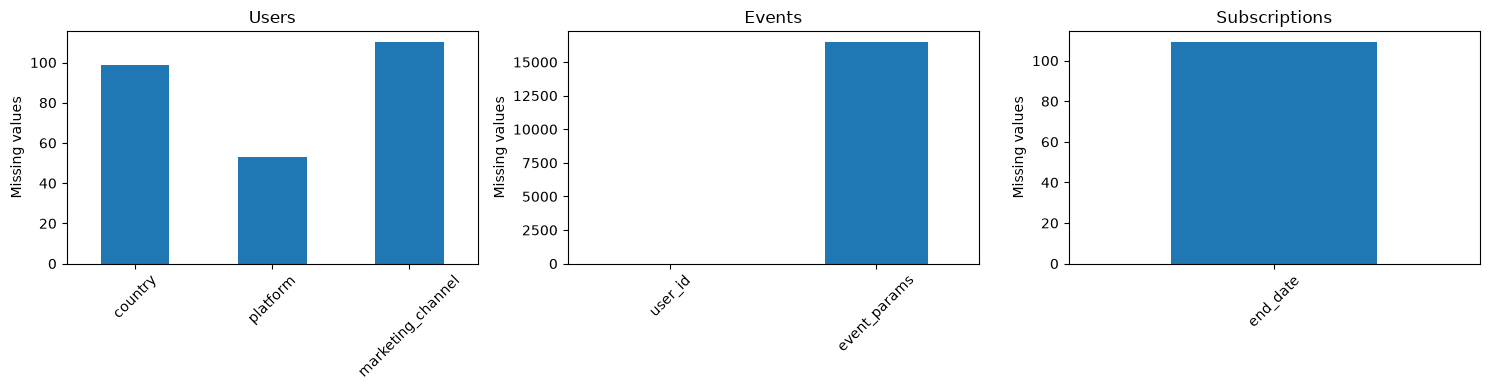

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, df) in zip(axes, {
    "Users": users_clean,
    "Events": events_clean,
    "Subscriptions": subscriptions_clean
}.items()):
    missing = df.isna().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        missing.plot(kind="bar", ax=ax)
        ax.set_ylabel("Missing values")
    else:
        ax.text(0.5, 0.5, "No missing values",
                ha="center", va="center")

    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## **2 частина**

### 7. Інтеграція мовної моделі (LLM API)
Підключення AI для автоматичної інтерпретації результатів EDA.

In [16]:

%pip install -U google-genai



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:

from google import genai
from getpass import getpass
from google.genai import errors

import json
from IPython.display import Markdown, display

api_key = getpass("Введіть Gemini API key: ")
client = genai.Client(api_key=api_key)

print("Gemini API client initialized!")


Введіть Gemini API key:  ········


Gemini API client initialized!


In [12]:

for model in client.models.list():
    if "generateContent" in (model.supported_actions or []):
        print(model.name)


models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

In [11]:
print("Надсилаємо запит до Gemini...", flush=True)

try:
    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents="Привіт! Напиши: AI-аналітик працює."
    )

    print("Відповідь отримано:")
    print(response.text)

except errors.APIError as e:
    print(f"Помилка API: {e.code}")
    print(e.message)


Надсилаємо запит до Gemini...
Відповідь отримано:
Привіт! AI-аналітик працює. 🚀



### 8. AI-інтерпретація результатів EDA
Автоматичне формування аналітичних висновків і рекомендацій за допомогою Gemini.


In [14]:


MODEL_NAME = "gemini-3.5-flash-lite"

def ai_interpret_eda(df, name="Dataset"):
    report = {
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicates": int(df.duplicated().sum()),
        "missing": df.isna().sum().astype(int).to_dict(),
        "missing_percent": (
            df.isna().mean() * 100
        ).round(2).to_dict(),
        "top_categories": {}
    }

    categorical = df.select_dtypes(
        include=["object", "string", "category"]
    )

    for col in categorical.columns:
        report["top_categories"][col] = (
            df[col].value_counts()
            .head(5).to_dict()
        )

    for col in df.select_dtypes(include="number").columns:
        if col.endswith("_id"):
            continue

        values = df[col].dropna()
        if not values.empty:
            report[col + "_statistics"] = {
                "min": float(values.min()),
                "max": float(values.max()),
                "mean": round(float(values.mean()), 2)
            }

    prompt = f"""
Ти AI-асистент продуктового аналітика.

Проаналізуй наведені результати EDA:
{json.dumps(report, ensure_ascii=False, indent=2)}

Сформуй українською мовою:

1. Короткий огляд набору даних.
2. Основні проблеми якості даних.
3. Три аналітичні висновки.
4. Три рекомендації для подальшої роботи.

Правила:
- Використовуй лише передані числові показники.
- Не вигадуй значення та причини аномалій.
- Відокремлюй факти від припущень.
- Пиши коротко та зрозуміло.
"""

    print(f"Аналізуємо {name} за допомогою Gemini...",
          flush=True)

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text


In [15]:

result_users = ai_interpret_eda(users_clean, "Users")

display(Markdown(result_users))


Аналізуємо Users за допомогою Gemini...


Привіт! Як AI-асистент продуктового аналітика, підготував для тебе структурований аналіз на основі наданих даних EDA.

---

### 1. Короткий огляд набору даних
Набір даних **`Users`** містить **4 030** рядків та **5** стовпчиків. Основні характеристики:
* **Часові рамки / ідентифікація:** `user_id` та `registration_date` не мають пропусків (0%).
* **Географія:** лідером серед країн є UA (995 користувачів), за нею йдуть PL (416), DE (351), US (311) та FR (261).
* **Платформи:** трафік поділений між iOS (2 041) та Android (1 936).
* **Маркетингові канали:** найбільше користувачів прийшли з organic (1 178), google_ads (854) та facebook_ads (743).

---

### 2. Основні проблеми якості даних
* **Дублікати:** у наборі зафіксовано **30 дублікатів** (близько 0.74% від загальної кількості рядків).
* **Пропущені значення (Missing values):**
  * `country`: 99 пропусків (2.46%).
  * `platform`: 53 пропуски (1.32%).
  * `marketing_channel`: 110 пропусків (2.73%).
  * `user_id` та `registration_date` пропусків не мають.

---

### 3. Три аналітичні висновки
1. **Фактичний розподіл платформ:** аудиторія користувачів практично рівномірно розподілена між мобільними операційними системами з невеликим переважанням iOS (2 041) над Android (1 936).
2. **Географічна концентрація:** Україна (UA) є наймасовішим ринком у базі (995 користувачів), що становить майже чверть від загального обсягу заповнених даних по країнах.
3. **Ефективність каналів залучення:** органічний трафік (`organic` — 1 178) є найбільшим джерелом нових користувачів, випереджаючи платні канали (`google_ads` — 854 та `facebook_ads` — 743).

---

### 4. Три рекомендації для подальшої роботи
1. **Очищення даних:** видалити або обробити 30 дублікатів перед проведенням будь-якого подальшого когортного чи продуктового аналізу.
2. **Робота з про пропусками:** дослідити причини виникнення пропусків у категоріальних змінних (`marketing_channel` — 110, `country` — 99, `platform` — 53) на рівні логування подій реєстрації у системі збору даних.
3. **Поглиблений сегментований аналіз:** виконати крос-аналіз залучення користувачів у розрізі платформ (`ios` / `android`) та маркетингових каналів (`organic`, `google_ads`, `facebook_ads`), враховуючи специфіку топ-країн (особливо UA).

In [17]:

result_events = ai_interpret_eda(events_clean, "Events")
display(Markdown(result_events))

result_subscriptions = ai_interpret_eda(
    subscriptions_clean, "Subscriptions"
)
display(Markdown(result_subscriptions))


Аналізуємо Events за допомогою Gemini...


Привіт! Як AI-асистент продуктового аналітика, підготував для тебе аналітичний звіт на основі наданих результатів EDA.

---

### 1. Короткий огляд набору даних
* Набір даних містить інформацію про події (`Events`), що складається з **42 420 рядків** та **4 колонок** (`user_id`, `event_name`, `event_timestamp`, `event_params`).
* Зафіксовано **5 унікальних типів подій**: `view_content` (24 983), `open_app` (12 390), `registration` (4 020), `start_trial` (645), та `purchase` (317).
* Параметри подій (`event_params`) розподілені між 5 категоріями контенту: відео, курси, статті, квізи та подкасти (усі мають приблизно по ~4,8–5 тисяч входжень).

### 2. Основні проблеми якості даних
* **Дублікати:** Виявлено **294 дублікати** у наборі даних.
* **Пропущені значення (Missing values):**
  * `user_id`: пропущено **8 значень** (0.02%).
  * `event_params`: пропущено **16 465 значень** (**38.81%**).
  * Колонки `event_name` та `event_timestamp` не мають пропусків (0%).

### 3. Три аналітичні висновки (Факти)
1. **Згасаюча воронка подій:** Кількість подій послідовно зменшується від базових до цільових: від `view_content` (24 983) і `open_app` (12 390) до `registration` (4 020), `start_trial` (645) і фінального `purchase` (317).
2. **Нерівномірність логування параметрів:** Більше ніж третина всіх подій (38.81%) не містить жодних параметрів (`event_params`), тоді як решта записів рівномірно розподілена між п'ятьма типами контенту (в межах 4 879 – 5 031 подія на категорію).
3. **Наявність технічних аномалій збору даних:** У колонці `user_id` зафіксовано 8 пропущених ідентифікаторів користувачів при загальній кількості рядків понад 42 тисячі.

### 4. Три рекомендації для подальшої роботи
1. **Очищення даних:** Видалити або задокументувати **294 дублікати** перед проведенням детального когортного чи продуктового аналізу.
2. **Технічний аудит трекінгу:** Перевірити налаштування збору подій на клієнті/сервері через високий показник пропущених даних у `event_params` (**38.81%**).
3. **Обробка аномалій:** Визначити бізнес-логіку обробки 8 рядків із пропущеним `user_id` (видалити їх або маркувати як анонімні сесії) залежно від цілей подальшого дослідження.

Аналізуємо Subscriptions за допомогою Gemini...


Привіт! Як твій асистент продуктового аналітика, підготував структурований аналіз на основі наданих даних EDA.

---

### 1. Короткий огляд набору даних
* Набір даних містить інформацію про **323** підписки (рядки) та **7** колонки.
* У даних зафіксовано **2** валюти (USD — 305 разів, EUR — 18 разів) та **2** типи планів (monthly — 214, annual — 109).
* Статистика сум (`amount`): мінімальне значення — **-79.99**, максимальне — **79.99**, середнє значення — **31.9**.

### 2. Основні проблеми якості даних
* **Дублікати:** виявлено **6** дублікатів у наборі даних.
* **Пропущені значення:** у колонці `end_date` є **109** пропусків, що становить **33.75%** від загальної кількості рядків. В інших колонках пропуски відсутні (0%).
* **Аномалії у числових даних:** у колонці `amount` мінімальне значення є від’ємним (**-79.99**), тоді як максимальне становить **79.99**.

### 3. Три аналітичні висновки
* **Висновок 1 (структура планів):** Кількість пропущених значень у `end_date` (109) збігається з кількістю підписок з річним планом (`annual` — 109). 
* **Висновок 2 (домінуюча валюта та план):** Основна частина транзакцій здійснюється в USD (305 із 323), а найпоширенішим типом підписки є щомісячна (`monthly` — 214 із 323).
* **Висновок 3 (аномалії платежів):** У фінансових даних присутні від’ємні суми платежів (мінімум -79.99), які за абсолютним значенням дорівнюють максимуму (79.99).

### 4. Три рекомендації для подальшої роботи
* **Рекомендація 1:** Видалити або детально дослідити виявлені **6** дублікатів перед проведенням подальших розрахунків.
* **Рекомендація 2:** Провести валідацію колонки `amount` через наявність від’ємних значень (-79.99) та з'ясувати, чи є це поверненнями коштів (refunds), чи помилкою введення даних.
* **Рекомендація 3:** Перевірити логіку заповнення `end_date` для річних підписок (`annual`), оскільки всі 109 пропусків у цій колонці припадають саме на них.

### 9. Генерація аналітичних гіпотез
Формування гіпотез щодо поведінки користувачів, конверсій та підписок за допомогою Gemini.

In [18]:

users_base = users_clean.drop_duplicates(
    subset=["user_id"]
).copy()

subscribers = set(subscriptions_clean["user_id"].dropna())

users_base["has_subscription"] = (
    users_base["user_id"].isin(subscribers)
)

platform_stats = users_base.groupby(
    "platform", dropna=False
).agg(
    users=("user_id", "count"),
    subscribers=("has_subscription", "sum")
)

platform_stats["conversion_rate"] = (
    platform_stats["subscribers"] /
    platform_stats["users"] * 100
).round(2)

channel_stats = users_base.groupby(
    "marketing_channel", dropna=False
).agg(
    users=("user_id", "count"),
    subscribers=("has_subscription", "sum")
)

channel_stats["conversion_rate"] = (
    channel_stats["subscribers"] /
    channel_stats["users"] * 100
).round(2)

print("Конверсія за платформами:")
display(platform_stats)

print("Конверсія за маркетинговими каналами:")
display(channel_stats)


Конверсія за платформами:


,users,subscribers,conversion_rate
platform,,,
android,1920,179,9.32
ios,2027,133,6.56
NaN,53,3,5.66


Конверсія за маркетинговими каналами:


,users,subscribers,conversion_rate
marketing_channel,,,
apple_search,301,26,8.64
email,337,23,6.82
facebook_ads,739,58,7.85
google_ads,851,61,7.17
organic,1165,97,8.33
referral,497,38,7.65
NaN,110,12,10.91


In [20]:


def suggest_hypotheses(platform_stats, channel_stats):
    data = {
        "platforms": platform_stats.reset_index().to_dict(
            orient="records"
        ),
        "channels": channel_stats.reset_index().to_dict(
            orient="records"
        )
    }

    prompt = f"""
Ти AI-аналітик мобільного застосунку.

Ось статистика користувачів і підписок:
{json.dumps(data, ensure_ascii=False, indent=2, default=str)}

Запропонуй 7 аналітичних гіпотез.

Для кожної гіпотези вкажи:
1. Формулювання гіпотези.
2. На яких числових показниках вона базується.
3. Як її можна перевірити за допомогою даних.
4. Яку користь перевірка дасть Product Manager.

Правила:
- Не вигадуй числових показників.
- Не називай гіпотези доведеними фактами.
- Не роби висновків про причинність.
- Враховуй розміри сегментів.
- Пиши коротко українською мовою.
"""

    print("Gemini генерує аналітичні гіпотези...",
          flush=True)

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text


In [21]:

hypotheses = suggest_hypotheses(
    platform_stats,
    channel_stats
)

display(Markdown(hypotheses))


Gemini генерує аналітичні гіпотези...


Привіт! Як AI-аналітик мобільного застосунку, пропоную 7 аналітичних гіпотез на основі наданих даних.

---

### Гіпотеза 1: Конверсія платформи Android вища за iOS
1. **Формулювання:** Користувачі Android частіше оформлюють підписку, ніж користувачі iOS.
2. **Показники:** Конверсія Android (9.32%) проти iOS (6.56%); користувачі (1920 vs 2027) та підписники (179 vs 133).
3. **Перевірка:** Провести А/B тестування або порівняти воронки продажу підписок окремо для кожної ОС для виявлення етапів відтоку.
4. **Користь для PM:** Допоможе оптимізувати платіжний шлюз або UI пейволу для iOS-користувачів для вирівнювання конверсії.

### Гіпотеза 2: Потенціал оптимізації Apple Search Ads
2. **Формулювання:** Рекламний канал `apple_search` генерує найвищу конверсію серед усіх каналів за меншої бази користувачів.
3. **Показники:** Конверсія `apple_search` (8.64%) за 301 користувача та 26 підписників.
4. **Перевірка:** Проаналізувати якість трафіку та рентабельність при збільшенні рекламного бюджету на цей канал.
5. **Користь для PM:** Дасть підґрунтя для перерозподілу маркетингового бюджету на користь масштабування `apple_search`.

### Гіпотеза 3: Ефективність невідомих джерел трафіку
3. **Формулювання:** Сегмент каналу з невизначеним значенням (`NaN`) має найвищу конверсію у підписку.
4. **Показники:** Конверсія `NaN` у каналах (10.91%) при 110 користувачах і 12 підписниках.
5. **Перевірка:** Налагодити систему трекінгу UTM-міток, щоб ідентифікувати джерело трафіку для цих 110 користувачів.
6. **Користь для PM:** Дозволить знайти та масштабувати приховане джерело високоефективного трафіку.

### Гіпотеза 4: Масштаб каналу `organic`
4. **Формулювання:** Органічний трафік забезпечує найбільший абсолютний приріст підписників завдяки об'єму аудиторії.
5. **Показники:** 1165 користувачів і 97 підписників при конверсії 8.33% (найбільша кількість підписників серед усіх каналів).
6. **Перевірка:** Дослідити фактори, що впливають на органічний притік (ASO, згадки в ЗМІ, рев'ю), та їхній зв'язок із конверсією.
7. **Користь для PM:** Допоможе фокусуватися на покращенні ASO-оптимізації для стабільного залучення найприбутковішої аудиторії.

### Гіпотеза 5: Низька ефективність каналу `email`
5. **Формулювання:** Email-розсилки демонструють найнижчу конверсію у підписку серед відомих маркетингових каналів.
6. **Показники:** Конверсія `email` (6.82%) при 337 користувачах і 23 підписниках.
7. **Перевірка:** Провести сегментацію бази, A/B тестування тем листів, офферів та часу відправки.
8. **Користь для PM:** Дасть змогу покращити retention та конверсію існуючої бази лідів або скоротити витрати на цей канал.

### Гіпотеза 6: Частка нерозподілених даних за платформами
6. **Формулювання:** Певна частина користувачів взаємодіє з додатком із платформ, які не вдалося коректно визначити (`NaN`).
7. **Показники:** Платформа `NaN` містить 53 користувачів, 3 підписників та конверсію 5.66%.
8. **Перевірка:** Провести технічний аудит аналітичного SDK (наприклад, Firebase/Amplitude) щодо збору параметрів `device_os`.
9. **Користь для PM:** Підвищить точність даних для прийняття подальших продуктових рішень.

### Гіпотеза 7: Потенціал масштабних платних каналів (`google_ads` та `facebook_ads`)
7. **Формулювання:** Платні канали `google_ads` та `facebook_ads` генерують найбільшу кількість користувачів, але їхня конверсія нижча за органіку та Apple Search.
8. **Показники:** `google_ads` (851 користувач, 61 підписник, 7.17%); `facebook_ads` (739 користувачів, 58 підписників, 7.85%).
9. **Перевірка:** Проаналізувати креативи, лендинги та когортний LTV користувачів із цих каналів порівняно з витратами на рекламу (CAC).
10. **Користь для PM:** Допоможе оптимізувати рекламні кампанії для покращення якості залученої аудиторії.

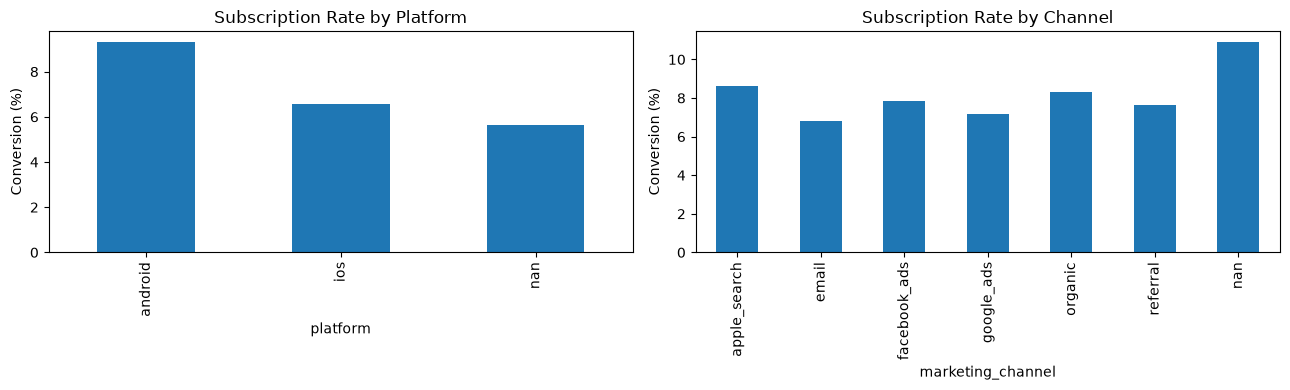

In [22]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

platform_stats["conversion_rate"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Subscription Rate by Platform")
axes[0].set_ylabel("Conversion (%)")

channel_stats["conversion_rate"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Subscription Rate by Channel")
axes[1].set_ylabel("Conversion (%)")

plt.tight_layout()
plt.show()



### 10. Аналіз аномальних змін показників
Виявлення різких змін активності користувачів та їх інтерпретація за допомогою Gemini.


In [23]:

daily_events = (
    events_clean
    .dropna(subset=["event_timestamp"])
    .groupby(events_clean["event_timestamp"].dt.date)
    .size()
    .reset_index(name="event_count")
)

daily_events.columns = ["date", "event_count"]
daily_events["date"] = pd.to_datetime(daily_events["date"])

daily_events["change_pct"] = (
    daily_events["event_count"].pct_change() * 100
).round(2)

anomalies = daily_events[
    daily_events["change_pct"].abs() > 30
].copy()

print("Щоденна активність:")
display(daily_events.head(10))

print("Виявлені аномальні зміни:")
display(anomalies)


Щоденна активність:


,date,event_count,change_pct
0,2026-01-01,43,NaN
1,2026-01-02,77,79.07
2,2026-01-03,79,2.60
3,2026-01-04,89,12.66
4,2026-01-05,97,8.99
5,2026-01-06,89,-8.25
6,2026-01-07,111,24.72
7,2026-01-08,163,46.85
8,2026-01-09,96,-41.10
9,2026-01-10,135,40.62


Виявлені аномальні зміни:


,date,event_count,change_pct
1,2026-01-02,77,79.07
7,2026-01-08,163,46.85
8,2026-01-09,96,-41.10
9,2026-01-10,135,40.62
11,2026-01-12,182,37.88
34,2026-02-04,199,41.13
39,2026-02-09,148,-33.03
40,2026-02-10,228,54.05
62,2026-03-04,231,38.32
66,2026-03-08,236,46.58


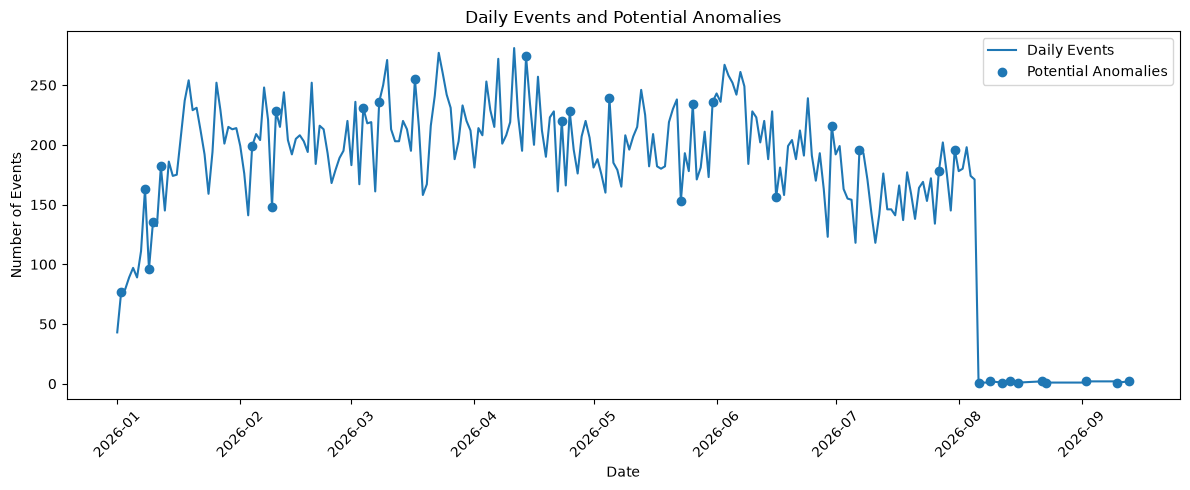

In [24]:

plt.figure(figsize=(12, 5))

plt.plot(
    daily_events["date"],
    daily_events["event_count"],
    label="Daily Events"
)

plt.scatter(
    anomalies["date"],
    anomalies["event_count"],
    label="Potential Anomalies"
)

plt.title("Daily Events and Potential Anomalies")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [25]:

def explain_metric_drop(daily_data, anomaly_data):
    report = {
        "daily_statistics": daily_data[
            ["date", "event_count", "change_pct"]
        ].assign(
            date=lambda x: x["date"].dt.strftime("%Y-%m-%d")
        ).to_dict(orient="records"),
        "anomalies": anomaly_data[
            ["date", "event_count", "change_pct"]
        ].assign(
            date=lambda x: x["date"].dt.strftime("%Y-%m-%d")
        ).to_dict(orient="records")
    }

    prompt = f"""
Ти AI-аналітик мобільного застосунку.

Проаналізуй динаміку кількості подій:
{json.dumps(report, ensure_ascii=False, default=str)}

Сформуй українською мовою:
1. Короткий опис динаміки активності.
2. Найбільші зростання та падіння з датами.
3. Можливі гіпотези щодо причин змін.
4. Три рекомендації щодо перевірки аномалій.

Не вигадуй чисел і не називай гіпотези
доведеними причинами змін.
Враховуй, що перший і останній день
можуть містити неповні дані.
Пиши коротко.
"""

    print("Gemini аналізує зміни активності...",
          flush=True)

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text


In [26]:

anomaly_report = explain_metric_drop(
    daily_events,
    anomalies
)

display(Markdown(anomaly_report))


Gemini аналізує зміни активності...


Як AI-аналітик мобільного застосунку, підготував для вас стисткий звіт на основі наданих даних.

### 1. Короткий опис динаміки активності
* **Січень – липень:** Спостерігається стабільний рівень активності з коливаннями переважно в межах 150–270 подій на день (після стартового нарощування в січні з мінімуму 43 події).
* **Серпень – вересень:** Відбувається критичне та різке зниження кількості подій до мінімальних значень (1–2 події на день), що свідчить про фактичну зупинку збору даних або відтік користувачів.

### 2. Найбільші зростання та падіння (за відсотками)
* **Найбільші зростання:**
  * 02.01.2026: +79.07% (77 подій)
  * 30.06.2026: +75.61% (216 подій)
  * 07.07.2026: +66.10% (196 подій)
  * 10.02.2026: +54.05% (228 подій)
* **Найбільші падіння:**
  * 06.08.2026: -99.42% (1 подія)
  * 09.01.2026: -41.10% (96 подій)
  * 23.05.2026: -35.71% (153 події)
  * 09.02.2026: -33.03% (148 подій)

### 3. Можливі гіпотези щодо причин змін
* Технічні проблеми зі збором або відправкою аналітики (краш SDK, блокування трекерів, проблеми на бекенді), особливо на тлі різкого обвалу в серпні.
* Релізи оновлень застосунку, які могли зламати логування подій або змінити логіку користувацьких сценаріїв.
* Маркетингові кампанії або рекламні залучення, що пояснюють локальні піки активності (наприклад, у січні та червні-липні).
* Органічні коливання активності користувачів або сезонність.
* Неповні дані за першу (01.01) та останню (13.09) дати через зріз у неповні години доби.

### 4. Три рекомендації щодо перевірки аномалій
1. **Перевірити роботу SDK аналітики:** Зробити технічний аудит подій у системі збору даних (наприклад, Amplitude, Firebase, Mixpanel) та перевірити наявність помилок у коді застосунку, починаючи з 6 серпня.
2. **Звірити дані з релізами:** Зіставити дати різких стрибків і падінь (особливо серпневий обвал) із графіком випуску оновлень застосунку в App Store / Google Play та змінами на сервері.
3. **Проаналізувати логи серверів та маркетинг:** Перевірити активність рекламних кампаній у періоди піків (січень, червень-липень) та порівняти графік подій із метриками активних користувачів (DAU) і технічними логами серверу.



### 10.1. Аналіз падіння активності за сегментами
Порівняння кількості подій до та після падіння за платформами, країнами й маркетинговими каналами.



In [39]:

users_info = users_clean.drop_duplicates(
    subset=["user_id"]
)[["user_id", "platform", "country", "marketing_channel"]]

events_analysis = events_clean.merge(
    users_info,
    on="user_id",
    how="left",
    validate="many_to_one"
)

events_analysis["date"] = (
    events_analysis["event_timestamp"].dt.normalize()
)

print("Кількість подій:", len(events_analysis))
display(events_analysis.head())


Кількість подій: 42420


,user_id,event_name,event_timestamp,event_params,platform,country,marketing_channel,date
0,3649.0,view_content,2026-07-04 04:34:56,content_type=video,ios,FR,organic,2026-07-04
1,4771.0,view_content,2026-05-16 09:33:00,content_type=video,android,CA,facebook_ads,2026-05-16
2,1785.0,view_content,2026-04-09 20:42:00,content_type=course,ios,US,facebook_ads,2026-04-09
3,1269.0,view_content,2026-07-14 05:56:10,content_type=quiz,android,US,organic,2026-07-14
4,2043.0,view_content,2026-04-01 22:13:11,content_type=podcast,android,PL,facebook_ads,2026-04-01


In [40]:

before_start = pd.Timestamp("2026-07-30")
before_end = pd.Timestamp("2026-08-05")

after_start = pd.Timestamp("2026-08-06")
after_end = pd.Timestamp("2026-08-12")

def segment_analysis(df, column):
    before = df[
        df["date"].between(before_start, before_end)
    ].groupby(column, dropna=False).size()

    after = df[
        df["date"].between(after_start, after_end)
    ].groupby(column, dropna=False).size()

    result = pd.DataFrame({
        "before": before,
        "after": after
    }).fillna(0).astype(int)

    result["change"] = result["after"] - result["before"]
    total_change = result["change"].sum()

    result["contribution_pct"] = (
        result["change"] / total_change * 100
        if total_change != 0 else 0.0
    )

    return result.sort_values("change")

platform_drop = segment_analysis(events_analysis, "platform")
country_drop = segment_analysis(events_analysis, "country")
channel_drop = segment_analysis(events_analysis, "marketing_channel")

print("За платформами:")
display(platform_drop.round(2))

print("За країнами:")
display(country_drop.head(10).round(2))

print("За маркетинговими каналами:")
display(channel_drop.round(2))


За платформами:


,before,after,change,contribution_pct
platform,,,,
ios,661,4,-657,53.11
android,564,1,-563,45.51
NaN,17,0,-17,1.37


За країнами:


,before,after,change,contribution_pct
country,,,,
UA,216,1,-215,17.38
ES,119,0,-119,9.62
PL,104,1,-103,8.33
US,99,2,-97,7.84
DE,94,0,-94,7.60
IT,89,0,-89,7.19
FR,77,0,-77,6.22
BR,73,0,-73,5.90
GB,69,0,-69,5.58


За маркетинговими каналами:


,before,after,change,contribution_pct
marketing_channel,,,,
organic,409,1,-408,32.98
facebook_ads,230,0,-230,18.59
google_ads,202,2,-200,16.17
referral,175,1,-174,14.07
apple_search,122,0,-122,9.86
email,77,1,-76,6.14
NaN,27,0,-27,2.18


In [41]:

def explain_segment_drop():
    data = {
        "period_before": "2026-07-30 — 2026-08-05",
        "period_after": "2026-08-06 — 2026-08-12",
        "platforms": platform_drop.reset_index().to_dict(
            orient="records"
        ),
        "countries": country_drop.reset_index().to_dict(
            orient="records"
        ),
        "channels": channel_drop.reset_index().to_dict(
            orient="records"
        )
    }

    prompt = f"""
Ти AI-аналітик мобільного застосунку.

Проаналізуй зміну кількості подій за сегментами:
{json.dumps(data, ensure_ascii=False, default=str)}

Визнач:
1. Яка платформа найбільше вплинула на падіння.
2. Які країни та канали зробили найбільший внесок.
3. Можливі гіпотези причин змін.
4. Три рекомендації для подальшої перевірки.

Використовуй лише передані числові показники.
Не вигадуй причин падіння.
Розрізняй факти й припущення.
Пиши коротко українською мовою.
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text

segment_report = explain_segment_drop()
display(Markdown(segment_report))


Привіт! Як AI-аналітик мобільного застосунку, підготував короткий звіт за результатами порівняння періодів **30.07.2026 — 05.08.2026** та **06.08.2026 — 12.08.2026**. Загалом зафіксовано різке падіння кількості подій практично до нуля по всіх сегментах.

### 1. Платформа, що найбільше вплинула на падіння
* **iOS:** Забезпечила найбільший внесок у падіння — **53.11%** (зменшення на 657 подій: з 661 до 4).
* Для порівняння, Android склав 45.51% (падіння на 563 події: з 564 до 1).

### 2. Країни та канали з найбільшим внеском
**Країни (ТОП-3 за внеском у падіння):**
1. **UA / Україна / ua / Ukraine** (сумарно по всіх написаннях): найбільший внесок серед регіонів. Тільки сегмент "UA" знизився на 215 подій (**17.38%** загального внеску), плюс додаткові спади зафіксовані в інших варіаціях назви країни.
2. **ES (Іспанія):** внесок **9.62%** (падіння на 119 подій, з 119 до 0).
3. **PL / Poland (Польща):** сумарний внесок понад **11.8%** (тільки "PL" дало 8.33%, зменшення на 103 події).

**Маркетингові канали (ТОП-3 за внеском у падіння):**
1. **Organic:** внесок **32.98%** (падіння на 408 подій: з 409 до 1).
2. **Facebook Ads:** внесок **18.59%** (падіння на 230 подій: з 230 до 0).
3. **Google Ads:** внесок **16.17%** (падіння на 200 подій: з 202 до 2).

---

### 3. Можливі гіпотези причин змін (припущення)
* **Технічний збій / Проблема з трекінгом:** Повну зупинку подій (майже 100% падіння по всіх платформах, каналах та географії одночасно) міг спричинити збій SDK аналітики, оновлення додатку, що зламало емісію подій, або блокування подій на сервері збору даних.
* **Зупинка маркетингової активності:** Оскільки платні канали (Facebook Ads, Google Ads) впали до нуля, це може свідчити про повне призупинення рекламних кампаній або вичерпання бюджетів.

---

### 4. Три рекомендації для подальшої перевірки
1. **Перевірити технічну інтеграцію:** Переконатися, що SDK аналітики працює коректно і не було випуску нових релізів додатку 06.08.2026, які блокують надсилання подій.
2. **Перевірити статус рекламних кабінетів:** Уточнити у медіабаєрів/маркетинг-команди, чи не зупинялися рекламні кампанії у Facebook та Google з 6 серпня.
3. **Проаналізувати інші метрики:** Перевірити дані щодо активних користувачів (DAU), кількості завантажень з магазинів (App Store / Google Play) та показників крашів (crash-rate) за цей самий період, щоб зрозуміти, чи впала реальна активність користувачів, чи зникли лише самі події аналітики.


### 11. Формування підсумкового AI-звіту
Узагальнення результатів EDA, конверсій та аномалій за допомогою Gemini.


In [42]:


def generate_summary():
    before_count = int(platform_drop["before"].sum())
    after_count = int(platform_drop["after"].sum())

    change_pct = (
        round((after_count - before_count) / before_count * 100, 2)
        if before_count > 0 else None
    )

    summary_data = {
        "total_users": int(users_base["user_id"].nunique()),
        "total_events": int(len(events_clean)),
        "total_subscriptions": int(len(subscriptions_clean)),
        "users_with_subscription_records": int(
            subscriptions_clean["user_id"].nunique()
        ),
        "platform_conversion": platform_stats[
            "conversion_rate"
        ].round(2).to_dict(),
        "channel_conversion": channel_stats[
            "conversion_rate"
        ].round(2).to_dict(),
        "daily_anomalies": anomalies.assign(
            date=anomalies["date"].dt.strftime("%Y-%m-%d")
        ).to_dict(orient="records"),
        "segment_analysis": {
            "period_before": "2026-07-30 — 2026-08-05",
            "period_after": "2026-08-06 — 2026-08-12",
            "events_before": before_count,
            "events_after": after_count,
            "change_pct": change_pct,
            "platforms": platform_drop.reset_index().to_dict(
                orient="records"
            ),
            "countries": country_drop.reset_index().to_dict(
                orient="records"
            ),
            "marketing_channels": channel_drop.reset_index().to_dict(
                orient="records"
            )
        }
    }

    prompt = f"""
Ти продуктовий AI-аналітик мобільного застосунку.

Підготуй підсумковий аналітичний звіт для Product Manager.

Перевірені результати аналізу:
{json.dumps(summary_data, ensure_ascii=False, default=str)}

Структура звіту:

1. Загальна характеристика даних.
   Вкажи кількість користувачів, подій та записів про підписки.

2. Аналіз конверсій.
   Порівняй Android та iOS.
   Визнач канали з найвищими та найнижчими показниками.

3. Аналіз аномалій активності.
   Опиши найбільше одноденне падіння активності.
   Порівняй два семиденні періоди до та після падіння.

4. Аналіз падіння за сегментами.
   Визнач платформи, країни та маркетингові канали,
   які зробили найбільший внесок у зменшення кількості подій.

5. Три практичні рекомендації.

6. Короткий загальний висновок.

ВАЖЛИВО:
- Android та iOS — платформи.
- Apple Search, Email, Organic та інші — маркетингові канали.
- Не змішуй платформи з маркетинговими каналами.
- Використовуй лише передані числові показники.
- Не вигадуй назви країн чи додаткові категорії.
- Не об'єднуй категорії без підтвердження у даних.
- Не вигадуй причини падіння активності.
- Можливі причини позначай як гіпотези.
- Внесок сегмента у загальне падіння не є
  відсотком зниження активності самого сегмента.
- Користувач із записом про підписку не обов'язково
  має активну або успішно оплачену підписку.
- Не плутай одноденне падіння зі зміною за 7 днів.

Відповідай українською мовою.
Звіт має бути структурованим, стислим і зрозумілим.
"""

    print("Gemini формує оновлений підсумковий звіт...",
          flush=True)

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )

    return response.text


In [43]:

final_report = generate_summary()

display(Markdown(final_report))


Gemini формує оновлений підсумковий звіт...


Ось підсумковий аналітичний звіт для Product Manager на основі перевірених результатів даних.

---

# 📊 Аналітичний звіт продукту

## 1. Загальна характеристика даних
* **Загальна кількість користувачів:** 4,000
* **Загальна кількість подій:** 42,420
* **Загальна кількість записів про підписки:** 323 (при цьому кількість користувачів із записами про підписки становить 317). 
* *Примітка:* Наявність запису про підписку не гарантує наявність активної чи успішно оплаченої підписки.

## 2. Аналіз конверсій
* **Порівняння платформ:**
  * **Android:** 9.32%
  * **iOS:** 6.56%
  *(Конверсія користувачів без зазначеної платформи (NaN) становить 5.66%).*
* **Маркетингові канали:**
  * **Найвищі показники конверсії:** канал без визначеної назви (`NaN`) — 10.91%, **Apple Search** — 8.64%, **Organic** — 8.33%.
  * **Найнижчі показники конверсії:** **Email** — 6.82%, **Google Ads** — 7.17%, **Referral** — 7.65% та **Facebook Ads** — 7.85%.

## 3. Аналіз аномалій активності
* **Найбільше одноденне падіння активності** зафіксовано **2026-08-06**: кількість подій різко скоротилася до 1, що становить падіння на **-99.42%** порівняно з попередніми показниками.
* **Порівняння семиденних періодів до та після падіння:**
  * Період до (2026-07-30 — 2026-08-05): 1,242 події.
  * Період після (2026-08-06 — 2026-08-12): 5 подій.
  * Загальна зміна між періодами: **-99.6%**.

## 4. Аналіз падіння за сегментами
Падіння активності у період з 30.07 по 12.08 розподілилося між такими сегментами:
* **Платформи:**
  * **iOS:** внесок у падіння — 53.11% (кількість подій зменшилася з 661 до 4).
  * **Android:** внесок — 45.51% (з 564 до 1).
  * `NaN`: внесок — 1.37% (з 17 до 0).
* **Країни (ТОП за внеском у загальне зменшення):**
  * **UA:** 17.38% (з 216 до 1)
  * **ES:** 9.62% (з 119 до 0)
  * **PL:** 8.33% (з 104 до 1)
  * **US:** 7.84% (з 99 до 2)
  * **DE:** 7.60% (з 94 до 0)
  * *(Також зафіксовано внески інших країн/варіантів написання згідно з вихідними даними: IT — 7.19%, FR — 6.22%, BR — 5.90%, GB — 5.58%, NL — 3.88%, Poland — 3.56%, Germany та CA — по 2.75%, ua — 2.43%, IN — 2.34%, United States — 1.46%, Україна — 1.21%, USA — 1.05%, `NaN` — 0.97%, Ukraine — 0.73%, UK — 0.65%, United Kingdom — 0.57%).*
* **Маркетингові канали:**
  * **Organic:** внесок — 32.98% (падіння з 409 до 1 події).
  * **Facebook Ads:** внесок — 18.59% (з 230 до 0).
  * **Google Ads:** внесок — 16.17% (з 202 до 2).
  * **Referral:** внесок — 14.07% (з 175 до 1).
  * **Apple Search:** внесок — 9.86% (з 122 до 0).
  * **Email:** внесок — 6.14% (з 77 до 1).
  * `NaN`: внесок — 2.18% (з 27 до 0).

## 5. Три практичні рекомендації
1. **Технічний аудит релізу/інфраструктури (Гіпотеза):** Оскільки 06.08.2026 сталася практично повна зупинка подій (-99.42%), необхідно терміново перевірити роботу SDK аналітики, статус сервісів збору даних або технічні проблеми у новому білді додатку.
2. **Оптимізація каналівacquisition та платформ:** Платформа Android демонструє вищу конверсію (9.32% проти 6.56% на iOS), а серед каналів лідирують Apple Search та Organic. Варто перерозподілити маркетингові бюджети на користь ефективніших каналів після стабілізації роботи застосунку.
3. **Робота з конверсією Email та Google Ads:** Показники конверсії в цих каналах одні з найнижчих (6.82% та 7.17% відповідно). Рекомендується провести A/B тестування креативів та оновлення воронки онбордингу для цих сегментів.

## 6. Короткий загальний висновок
Продукт має сталу базову активність і базову конверсію у підписки (біля 7–9% залежно від платформи/каналу). Проте критична аномалія на початку серпня 2026 року (падіння подій на ~99.6%) свідчить про системний або технічний збій (найімовірніше, проблеми на рівні трекінгу подій або критичний стан бекенду), що зачепив усі ключові ринки, платформи та канали (особливо Organic та Facebook Ads). Усунення цієї технічної проблеми є пріоритетним завданням для команди.

In [44]:

from pathlib import Path

Path("ai_analytics_report.md").write_text(
    final_report,
    encoding="utf-8"
)

print("Звіт збережено: ai_analytics_report.md")


Звіт збережено: ai_analytics_report.md



### 12. Тестування 
Порівняння відповідей Gemini на базовий та вдосконалений промпти.


In [45]:

test_data = {
    "platform_conversion": {
        "Android": round(float(
            platform_stats.loc["android", "conversion_rate"]
        ), 2),
        "iOS": round(float(
            platform_stats.loc["ios", "conversion_rate"]
        ), 2)
    },
    "marketing_channel_conversion": {
        "Apple Search": round(float(
            channel_stats.loc["apple_search", "conversion_rate"]
        ), 2),
        "Email": round(float(
            channel_stats.loc["email", "conversion_rate"]
        ), 2)
    },
    "largest_daily_event_drop": {
        "date": "2026-08-06",
        "change_pct": float(
            daily_events.loc[
                daily_events["date"] == pd.Timestamp("2026-08-06"),
                "change_pct"
            ].iloc[0]
        )
    },
    "weekly_event_comparison": {
        "period_before": "2026-07-30 — 2026-08-05",
        "period_after": "2026-08-06 — 2026-08-12",
        "events_before": int(platform_drop["before"].sum()),
        "events_after": int(platform_drop["after"].sum())
    },
    "segment_contributions": {
        "platforms": platform_drop["contribution_pct"].round(2).to_dict(),
        "countries": country_drop["contribution_pct"].round(2).to_dict(),
        "channels": channel_drop["contribution_pct"].round(2).to_dict()
    }
}

basic_prompt = f"""
Проаналізуй показники мобільного застосунку:
{json.dumps(test_data, ensure_ascii=False)}
"""

improved_prompt = f"""
Ти продуктовий аналітик.

Проаналізуй такі показники:
{json.dumps(test_data, ensure_ascii=False)}

Завдання:
1. Порівняй конверсії Android та iOS.
2. Визнач найвищу й найнижчу конверсії.
3. Опиши падіння активності користувачів.
4. Проаналізуй результати за сегментами.
5. Запропонуй три рекомендації.

Правила:
- Використовуй лише передані числа.
- Не вигадуй причини змін.
- Відокремлюй факти від гіпотез.
- Відповідай українською мовою.
- Пиши структуровано та коротко.
"""


In [46]:

def test_prompt(prompt):
    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt
    )
    return response.text

print("Тестування початкового промпту...", flush=True)
basic_result = test_prompt(basic_prompt)
display(Markdown("### Початковий промпт\n" + basic_result))

print("Тестування вдосконаленого промпту...", flush=True)
improved_result = test_prompt(improved_prompt)
display(Markdown("### Вдосконалений промпт\n" + improved_result))


Тестування початкового промпту...


### Початковий промпт
На основі наданих даних проведено аналіз ключових показників мобільного застосунку. Виявлено сильну сторону продукту, а також критичну технічну/маркетингову проблему, що сталася на початку серпня 2026 року.

---

### 1. Критична подія (Аномалія)
У даних зафіксовано катастрофічне падіння активності користувачів:
* **Дата:** 6 серпня 2026 року (`largest_daily_event_drop`).
* **Падіння:** `-99.42%`.
* **Порівняння тижнів:** 
  * До 6 серпня (30.07 — 05.08): **1 242 події**.
  * Після 6 серпня (06.08 — 12.12): всього **5 подій**.

> **Висновок:** 6 серпня сталася критична аварія. Це міг бути повний злам сервера, блокування застосунку в сторах, реліз критичного багу (crash loop) або відключення аналітичного трекера (SDK). Застосунок фактично припинив функціонувати.

---

### 2. Конверсія за платформами
* **Android:** 9.32%
* **iOS:** 6.56%

> **Висновок:** Android демонструє значно вищу конверсію (майже на 42% вище), ніж iOS. Це незвична ситуація для багатьох мобільних застосунків (де зазвичай лідирує iOS), що може свідчити про кращу оптимізацію воронки для Android-користувачів або специфіку цільової аудиторії.

---

### 3. Конверсія за маркетинговими каналами
* **Apple Search Ads:** 8.64%
* **Email-маркетинг:** 6.82%

> **Висновок:** Apple Search показує високу ефективність (цільові користувачі, які вже шукають схожий функціонал). Email також дає непогану конверсію, хоча обсяг цього каналу зазвичай менший.

---

### 4. Внесок сегментів (Segment Contributions)

#### А. Платформи (загальний обсяг трафіку/активності):
* **iOS:** 53.11%
* **Android:** 45.51%
* *Не вказано (NaN):* 1.37%

> *Цікавий інсайт:* Хоча конверсія на Android вища, за загальним обсягом аудиторії лідирує **iOS** (53.11%).

#### Б. Географія (Країни):
У даних є проблема з уніфікацією назв країн (дублюються варіанти на кшталт `UA`, `ua`, `Україна`, `Ukraine`, а також `PL` та `Poland`, `DE` та `Germany`, `US` та `USA` тощо). Проте топ-ринки очевидні:
1. **Україна** (сумарно UA + ua + Україна + Ukraine дають найбільшу частку — понад 21%).
2. **Іспанія (ES):** 9.62%
3. **Польща (PL + Poland):** ~11.9%
4. **США (US + USA + United States):** ~10.35%
5. **Німеччина (DE + Germany):** ~10.35%

> **Висновок:** Ядро аудиторії складають користувачі з України, Польщі, Іспанії, США та Німеччини. 
> ⚠️ *Рекомендація:* Терміново налаштувати нормалізацію (clean-up) даних у системі аналітики, оскільки назви країн пишуться в різних форматах, що спотворює точну звітність.

#### В. Маркетингові канали (Трафік):
1. **Organic (Органіка):** 32.98% (найбільший джерело)
2. **Facebook Ads:** 18.59%
3. **Google Ads:** 16.17%
4. **Referral (Реферали):** 14.07%
5. **Apple Search:** 9.86%
6. **Email:** 6.14%

> **Висновок:** Застосунок має здоровий мікс трафіку з сильним органічним припливом (~33%) та ефективним платним каналом у соцмережах (Facebook Ads випереджає Google Ads).

---

### Загальні рекомендації:
1. **Терміновий технічний аудит:** Головний пріоритет — з'ясувати причину падіння подій на 99.42% від 6 серпня 2026 року та відновити роботу сервісу/трекінгу.
2. **Очищення даних (Data Hygiene):** Виправити проблеми з передачею тегів країн (`UA`/`Україна`), щоб бачити реальний рейтинг топ-ринків.
3. **Масштабування Android:** Проаналізувати, чому конверсія на Android вища, і спробувати застосувати ці механіки на iOS-аудиторію.

Тестування вдосконаленого промпту...


### Вдосконалений промпт
Привіт! Як продуктовий аналітик, підготував для тебе структурований аналіз наданих даних.

---

### 1. Порівняння конверсій Android та iOS
* **Факти:** Конверсія платформи Android становить **9.32%**, тоді як iOS — **6.56%**. Конверсія Android вища за iOS на 2.76 відсоткових пункти.

### 2. Найвища й найнижча конверсії
* **Факти:** 
  * Найвища конверсія зафіксована на платформі **Android (9.32%)** серед платформ, та у каналі **Apple Search (8.64%)** серед маркетингових каналів.
  * Найнижча конверсія серед доступних для порівняння каналів та платформ зафіксована у каналі **Email (6.82%)** та на платформі **iOS (6.56%)**.

### 3. Опис падіння активності користувачів
* **Факти:** 
  * Найбільший денний обвал подій стався **2026-08-06** зі зміною у **-99.42%**.
  * Порівняння тижневих періодів показує різке скорочення подій: у період до (2026-07-30 — 2026-08-05) зафіксовано **1242** події, а після (2026-08-06 — 2026-08-12) — лише **5** подій.

### 4. Аналіз результатів за сегментами
* **Факти:**
  * **Платформи:** Найбільшу частку внеску мають iOS (**53.11%**) та Android (**45.51%**), не визначено (`NaN`) — **1.37%**.
  * **Країни:** Спостерігається дублювання та різна локалізація назв країн (наприклад, UA, ua, Україна, Ukraine). Сумарно лідирують регіони України (**17.38% + 2.43% + 1.21% + 0.73% = 21.75%**), далі йдуть Іспанія (**9.62%**), Польща (**8.33% + 3.56% = 11.89%**), США (**7.84% + 1.46% + 1.05% + 0.73% [Ukraine typo в оригіналі відкинуто] = 10.35%**) та інші. Не визначено (`NaN`) — **0.97%**.
  * **Канали:** Найбільший внесок у сегменті за каналами робить organic (**32.98%**), за ним ідуть facebook_ads (**18.59%**), google_ads (**16.17%**), referral (**14.07%**), apple_search (**9.86%**) та email (**6.14%**). Не визначено (`NaN`) — **2.18%**.

### 5. Рекомендації
* **Рекомендація 1 (Факт + Гіпотеза):** Оскільки дані містять дублікати та неструктуровані значення в країнах (UA, ua, Україна, Ukraine) і наявні `NaN` у всіх сегментах, **рекомендую** провести уніфікацію та валідацію збору аналітичних даних. *Гіпотеза:* це дозволить точніше оцінити реальний розподіл користувачів за країнами та каналами.
* **Рекомендація 2 (Факт):** З огляду на критичне падіння подій з 5 серпня на 99.42% (з 1242 до 5 подій на тиждень), **рекомендую** негайно перевірити технічну інфраструктуру трекінгу подій на предмет збоїв SDK, блокування аналітики чи технічного релізу, що зламав збір даних.
* **Рекомендація 3 (Факт):** З огляду на те, що конверсія Android (9.32%) вища за iOS (6.56%), а Apple Search показує високу конверсію (8.64%) при значній частці трафіку з iOS (53.11%), **рекомендую** провести детальний UX/UI аудит воронки на iOS з метою виявлення бар'єрів, які знижують її конверсію відносно Android.

In [52]:

corrected_prompt = f"""
Ти продуктовий AI-аналітик мобільного застосунку.

Проаналізуй перевірені показники:
{json.dumps(test_data, ensure_ascii=False)}

ВАЖЛИВО:
- Android та iOS — платформи.
- Apple Search та Email — маркетингові канали.
- Не порівнюй платформи з маркетинговими каналами.
- Використовуй тільки надані числові показники.
- Не вигадуй додаткові країни, назви чи категорії.
- Не об'єднуй назви країн без підтвердження в даних.
- Не вигадуй причини падіння активності.
- Не використовуй довільні ринкові нормативи.
- Розрізняй факти, гіпотези та рекомендації.
- Пропущені значення (NaN) не вважай окремими маркетинговими каналами.
- Не називай жодну причину падіння найбільш імовірною без підтверджувальних даних. Усі можливі причини подавай як гіпотези.
- Внесок сегмента (%) = зміна кількості подій у сегменті /
  загальна зміна кількості подій × 100.
- Це не частка сегмента в загальному обсязі даних до падіння.

Завдання:
1. Порівняй конверсії Android та iOS.
   Розрахуй різницю у відсоткових пунктах.

2. Порівняй конверсії Apple Search та Email.
   Визнач вищий і нижчий показники.

3. Опиши найбільше одноденне падіння
   активності із зазначенням дати.

4. Порівняй кількість подій за два семиденні періоди.
   Розрахуй відсоток зміни кількості подій.

5. Визнач платформи, країни та маркетингові канали,
   що зробили найбільший внесок у загальне падіння.

6. Запропонуй три рекомендації для перевірки.

Пояснюй, що внесок сегмента у загальне падіння
і відсоток зниження всередині сегмента — різні показники.

Відповідай коротко українською мовою.
Використовуй чіткі заголовки.
"""



In [53]:


corrected_result = test_prompt(corrected_prompt)

display(Markdown(
    "### Виправлений промпт\n" + corrected_result
))



### Виправлений промпт
### 1. Порівняння конверсій платформ
* **Показники:** Android — 9.32%, iOS — 6.56%.
* **Факти:** Конверсія на Android вища, ніж на iOS.
* **Різниця:** 2.76 відсоткових пункти (9.32% - 6.56%).

### 2. Порівняння конверсій маркетингових каналів
* **Показники:** Apple Search — 8.64%, Email — 6.82%.
* **Факти:** Конверсія каналу Apple Search вища, а каналу Email — нижча.

### 3. Найбільше одноденне падіння активності
* **Факти:** Найбільше одноденне падіння подій зафіксовано 2026-08-06 зі зміною на -99.42%.

### 4. Порівняння тижневих періодів
* **Періоди:** До падіння (2026-07-30 — 2026-08-05) зафіксовано 1242 події; після падіння (2026-08-06 — 2026-08-12) — 5 подій.
* **Факти:** Кількість подій зменшилася на 99.60% ((5 - 1242) / 1242 × 100).

### 5. Внесок сегментів у загальне падіння
*(Примітка: внесок сегмента розраховується як зміна кількості подій у сегменті до загальної зміни кількості подій і відрізняється від відсотка зниження всередині самого сегмента).*
* **Платформи з найбільшим внеском:** iOS (53.11%), Android (45.51%).
* **Країни з найбільшим внеском:** UA (17.38%), ES (9.62%), PL (8.33%).
* **Маркетингові канали з найбільшим внеском:** Organic (32.98%), Facebook_ads (18.59%), Google_ads (16.17%).

### 6. Рекомендації для перевірки
* **Гіпотеза 1:** Перевірити технічну доступність та коректність трекінгу подій на платформі iOS станом на 2026-08-06, оскільки вона має найбільший внесок у падіння.
* **Гіпотеза 2:** Дослідити зміни у джерелах трафіку для сегмента Organic та каналу Facebook_ads на предмет можливих зштовхнень з ботами або блокування аналітики.
* **Гіпотеза 3:** Перевірити георозподіл подій для країни UA на наявність локальних технічних чи мережевих збоїв, що збіглися з датою падіння.